In [ ]:
import sys
sys.path.append("..")
import matplotlib.pyplot as plt
import statsmodels.api as sm
from src.data import load_brent_spot
from src.features import log_returns

In notebook aa_forecast1.ipynb, shown that no significant correlation at any lag. Will test again for forecast of horizon = 5.

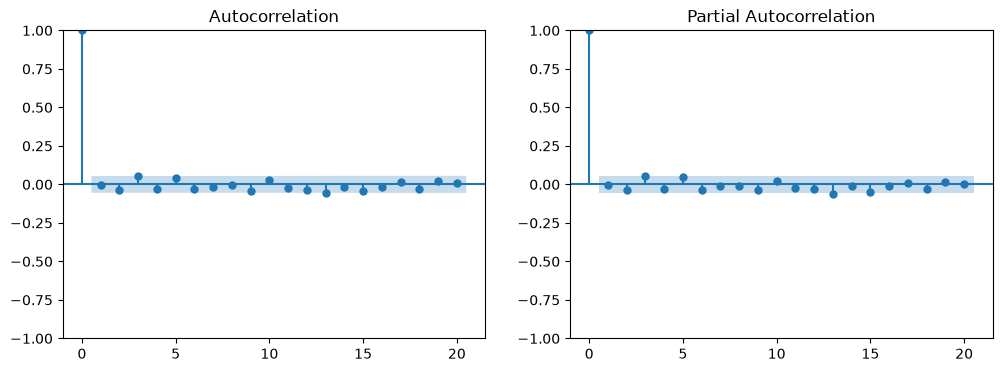

In [ ]:
spot = load_brent_spot(start="2000-01-01")
data = spot.copy()
data["log_return"] = log_returns(data, col="brent_spot")
data = data.dropna()

rolling_5_day_returns= data["log_return"].loc[:"2026-09-30"].rolling(5).sum() # each row adds the 5 behind it, then shows as a single 5-day log return
five_day_no_overlap = rolling_5_day_returns.iloc[::5].dropna() #only keeps every 5th row, this ensures no overlap in like day 5 and day 10's return.
# otherwise for example day 5 and day 6's return, would share 4 similar days towards their sums.

fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sm.graphics.tsa.plot_acf(five_day_no_overlap, lags=20, ax=axes[0])
sm.graphics.tsa.plot_pacf(five_day_no_overlap, lags=20, ax=axes[1])
plt.show()


Close no AR or MA signals. Don't have to consider AR MA family of models. Will keep AR1 for benchmark purposes.